<a href="https://colab.research.google.com/github/leozeze/LRP1_heart/blob/main/02_notebooks/02_celltype_overview.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02. 세포 유형별 LRP1, sheddase 발현

README의 **분석 1**에 해당합니다.

- 모든 세포 유형에서 유전자별 발현 세포 비율과 평균 발현량을 계산
- 섬유모세포가 다른 세포 유형보다 실제로 높은지 **공여자 단위**로 비교

01번 노트북에서 만든 작은 파일만 사용합니다. 그림과 표는 드라이브의 `05_presentation` 폴더에 `02_`로 시작하는 이름으로 저장됩니다.
(Colab에는 한글 글꼴이 없어 그림 안의 글자는 영어로 표기합니다.)

## 1. 준비

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT = Path('/content/drive/MyDrive/LRP1_heart')
SUBSET_FILE = PROJECT / '01_data' / 'subset' / 'lrp1_subset_v1.h5ad'
OUT = PROJECT / '05_presentation'
OUT.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [2]:
!pip -q install scanpy "pandas==2.2.3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scanpy as sc
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

## 2. 데이터 불러오기와 개요

In [3]:
ad = sc.read_h5ad(SUBSET_FILE)

TARGET = ['LRP1']
SHEDDASES = ['ADAM10', 'ADAM12', 'ADAM17', 'MMP14', 'MMP15', 'MMP16', 'MMP17', 'BACE1']
GENES = [g for g in TARGET + SHEDDASES if g in ad.var_names]
FB = 'Fibroblast'
assert FB in set(ad.obs['cell_type'].astype(str)), '세포 유형 이름을 확인하세요'

print(f'세포/핵 {ad.n_obs:,}개,  공여자 {ad.obs["donor"].nunique()}명,  세포 유형 {ad.obs["cell_type"].nunique()}종')
print('분석 유전자:', GENES)

세포/핵 704,296개,  공여자 22명,  세포 유형 12종
분석 유전자: ['LRP1', 'ADAM10', 'ADAM12', 'ADAM17', 'MMP14', 'MMP15', 'MMP16', 'MMP17', 'BACE1']


세포 유형별로 **세포로 측정된 것**과 **핵으로 측정된 것**이 각각 몇 개인지, 그리고 세포당 잡힌 RNA 총량의 중앙값을 봅니다.

- 심근세포와 지방세포는 거의 핵으로만 측정되어 있습니다.
- RNA 총량이 많은 세포 유형일수록 어떤 유전자든 검출되기 쉽습니다. 발현 세포 비율을 세포 유형끼리 비교할 때 염두에 둘 점입니다.

In [4]:
ct = ad.obs['cell_type'].astype(str)
src = ad.obs['cell_or_nuclei'].astype(str)
overview = pd.crosstab(ct, src)
depth = ad.obs.groupby([ct.values, src.values], observed=True)['total_counts'].median().unstack()
overview = overview.join(depth.round(0).add_prefix('median_counts_'))
overview.to_csv(OUT / '02_overview_cells_per_type.csv')
overview

,Cell,Nuclei,median_counts_Cell,median_counts_Nuclei
cell_type,,,,
Adipocyte,1,6346,1764.0,4724.0
Atrial Cardiomyocyte,826,45085,1258.0,4064.0
Endothelial cell,80398,51107,2026.0,1131.0
Fibroblast,3163,134892,3276.0,1667.0
Lymphatic Endothelial cell,231,1064,4383.0,1767.0
Lymphoid,11945,12977,1760.0,1254.0
Mast cell,1,1852,2650.0,898.0
Mesothelial cell,195,862,8531.0,2063.0
Mural cell,22641,81952,2171.0,1145.0


## 3. 세포 유형 이름 점검

논문(Litviňuková et al. 2020, Fig. 1c)의 표지 유전자가 해당 세포 유형에서 높게 나오는지 확인합니다.
대각선 방향으로 진한 점이 이어지면 세포 유형 이름이 제대로 붙어 있는 것입니다.

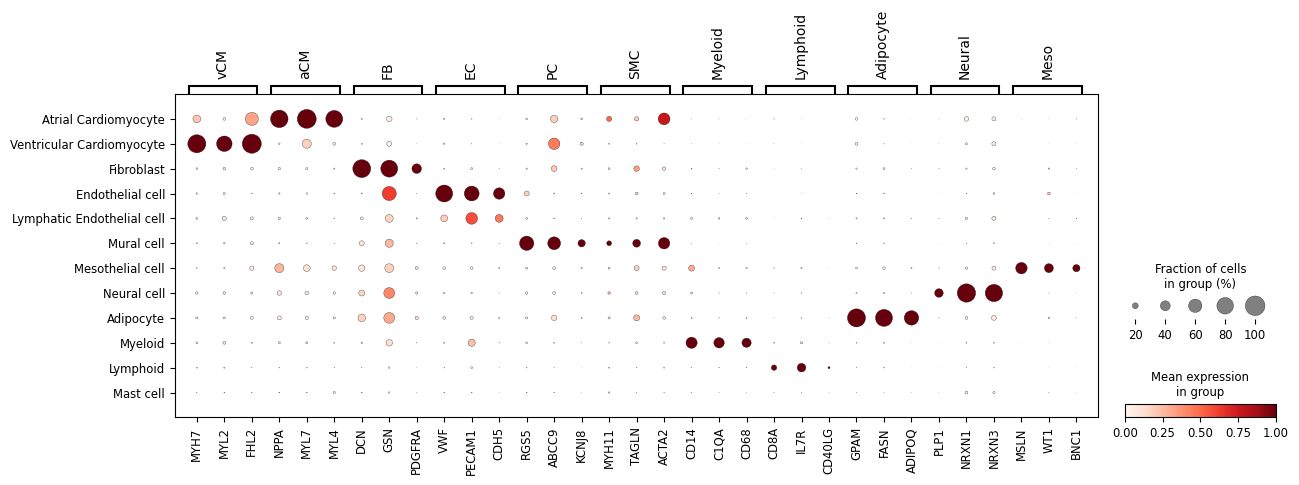

In [5]:
MARKERS = {
    'vCM': ['MYH7', 'MYL2', 'FHL2'], 'aCM': ['NPPA', 'MYL7', 'MYL4'],
    'FB': ['DCN', 'GSN', 'PDGFRA'], 'EC': ['VWF', 'PECAM1', 'CDH5'],
    'PC': ['RGS5', 'ABCC9', 'KCNJ8'], 'SMC': ['MYH11', 'TAGLN', 'ACTA2'],
    'Myeloid': ['CD14', 'C1QA', 'CD68'], 'Lymphoid': ['CD8A', 'IL7R', 'CD40LG'],
    'Adipocyte': ['GPAM', 'FASN', 'ADIPOQ'], 'Neural': ['PLP1', 'NRXN1', 'NRXN3'],
    'Meso': ['MSLN', 'WT1', 'BNC1'],
}
MARKERS = {k: [g for g in v if g in ad.var_names] for k, v in MARKERS.items()}
sc.pl.dotplot(ad, MARKERS, groupby='cell_type', standard_scale='var', show=False)
plt.savefig(OUT / '02_dotplot_markers.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. 세포 유형별 LRP1, sheddase 발현 (전체 세포 기준)

- **pct**: 그 유전자가 검출된 세포의 비율(%)
- **mean**: 평균 발현량(로그 정규화 값)

모든 공여자의 세포를 한데 모아 계산한 값입니다.

In [6]:
X = pd.DataFrame(ad[:, GENES].X.toarray(), columns=GENES, index=ad.obs_names)
pct = (X > 0).groupby(ct.values).mean().mul(100)
mean = X.groupby(ct.values).mean()
n = ct.value_counts().rename('n_cells')

by_type = pd.concat([n, pct.add_suffix('_pct'), mean.add_suffix('_mean')], axis=1)
by_type = by_type.sort_values('LRP1_pct', ascending=False)
by_type.round(3).to_csv(OUT / '02_by_cell_type.csv')

print('[발현 세포 비율 (%)]')
pct.loc[by_type.index].round(1)

[발현 세포 비율 (%)]


,LRP1,ADAM10,ADAM12,ADAM17,MMP14,MMP15,MMP16,MMP17,BACE1
Adipocyte,70.5,30.8,50.2,45.9,8.6,7.2,7.1,7.9,11.2
Fibroblast,52.7,23.5,10.5,27.8,11.7,0.3,15.6,1.3,7.1
Myeloid,44.6,39.4,0.8,30.7,8.4,0.4,1.1,1.1,3.7
Mesothelial cell,27.2,27.9,8.3,31.1,14.5,5.2,3.6,0.9,11.6
Neural cell,17.4,23.4,3.2,19.8,5.8,0.8,3.5,4.5,6.6
Ventricular Cardiomyocyte,12.8,43.9,11.3,26.1,0.4,4.4,1.1,0.1,8.0
Mural cell,11.9,12.7,0.6,13.4,3.8,0.2,7.5,0.6,3.7
Atrial Cardiomyocyte,6.6,52.9,6.9,31.3,1.0,5.0,0.8,0.2,8.3
Lymphatic Endothelial cell,4.2,50.0,2.4,19.8,11.3,0.8,17.1,4.9,3.6
Mast cell,2.1,13.3,28.5,10.3,0.3,0.0,1.5,0.3,1.5


도트 플롯: 점의 **크기**는 발현 세포 비율, **색**은 평균 발현량입니다. 세포 유형은 LRP1 발현 비율이 높은 순으로 정렬했습니다.

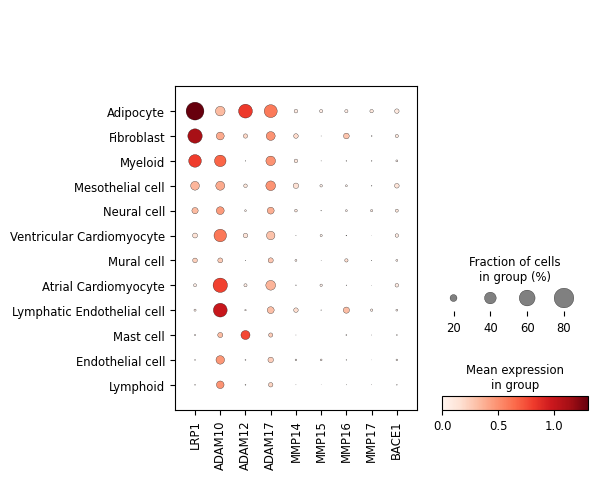

In [7]:
order = list(by_type.index)
sc.pl.dotplot(ad, GENES, groupby='cell_type', categories_order=order,
              cmap='Reds', show=False)
plt.savefig(OUT / '02_dotplot_LRP1_sheddase.png', dpi=200, bbox_inches='tight')
plt.show()

UMAP: 왼쪽은 세포 유형, 오른쪽은 LRP1 발현량입니다. cellxgene에서 보던 것과 같은 지도입니다.

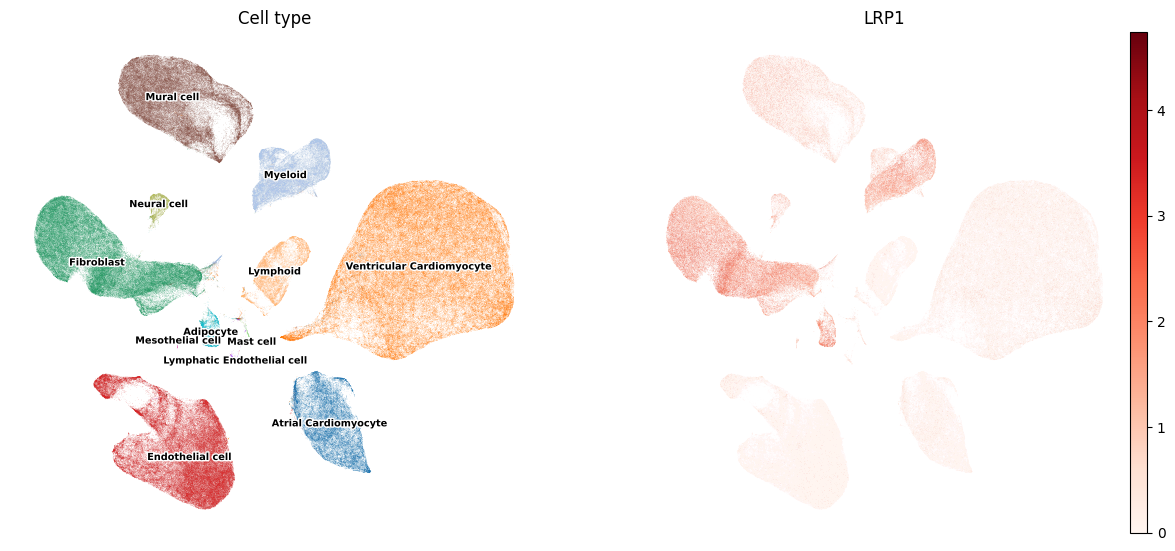

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc.pl.umap(ad, color='cell_type', ax=axes[0], show=False, legend_loc='on data',
           legend_fontsize=7, legend_fontoutline=2, frameon=False, title='Cell type')
sc.pl.umap(ad, color='LRP1', ax=axes[1], show=False, cmap='Reds', sort_order=False,
           frameon=False, title='LRP1')
plt.savefig(OUT / '02_umap_LRP1.png', dpi=200, bbox_inches='tight')
plt.show()

## 5. 공여자 단위 비교

위의 값은 70만 개 세포를 한데 모은 것이라, 세포가 많은 공여자 몇 명이 결과를 좌우할 수 있습니다.
그래서 **공여자 한 명 한 명에서 따로** 계산해 일관성을 봅니다.

- 측정 방식(세포/핵)에 따라 값이 달라지므로 나눠서 계산합니다.
- 한 공여자의 한 세포 유형에 세포가 50개 미만이면 값이 불안정하므로 제외합니다.

In [9]:
MIN_CELLS = 50
keys = [src.values, ad.obs['donor'].astype(str).values, ct.values]
names = ['source', 'donor', 'cell_type']

n_cells = X.groupby(keys).size().rename('n_cells')
d_pct = (X > 0).groupby(keys).mean().mul(100)
d_mean = X.groupby(keys).mean()
for t in (n_cells, d_pct, d_mean):
    t.index.names = names

donor = (d_pct.stack().rename('pct').to_frame()
         .join(d_mean.stack().rename('mean')))
donor.index.names = names + ['gene']
donor = donor.reset_index().merge(n_cells.reset_index(), on=names)
donor = donor[donor['n_cells'] >= MIN_CELLS].reset_index(drop=True)
donor.round(4).to_csv(OUT / '02_donor_level.csv', index=False)

print('공여자 수 (측정 방식별):')
print(donor.groupby('source')['donor'].nunique())
donor.head()

공여자 수 (측정 방식별):
source
Cell       7
Nuclei    22
Name: donor, dtype: int64


,source,donor,cell_type,gene,pct,mean,n_cells
0,Cell,D1,Endothelial cell,LRP1,0.000000,0.000000,85
1,Cell,D1,Endothelial cell,ADAM10,12.941176,0.267322,85
2,Cell,D1,Endothelial cell,ADAM12,0.000000,0.000000,85
3,Cell,D1,Endothelial cell,ADAM17,8.235294,0.184735,85
4,Cell,D1,Endothelial cell,MMP14,1.176471,0.021827,85


### LRP1: 공여자별 발현 세포 비율

점 하나가 공여자 한 명입니다. 상자가 위쪽에 있고 점들이 모여 있을수록, 그 세포 유형에서 여러 공여자에 걸쳐 일관되게 높다는 뜻입니다. 섬유모세포는 색으로 강조했습니다.

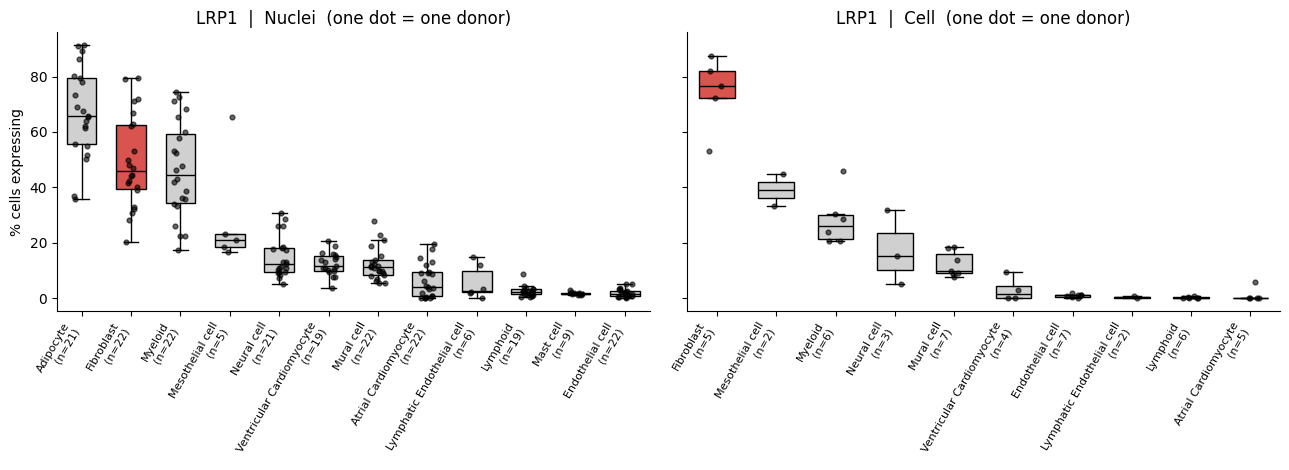

In [10]:
def donor_boxplot(gene, value='pct', ylabel='% cells expressing', fname=None):
    sources = [s for s in ['Nuclei', 'Cell'] if s in set(donor['source'])]
    fig, axes = plt.subplots(1, len(sources), figsize=(6.5 * len(sources), 4.8), sharey=True, squeeze=False)
    rng = np.random.default_rng(0)
    for ax, s in zip(axes[0], sources):
        d = donor[(donor['gene'] == gene) & (donor['source'] == s)]
        order = d.groupby('cell_type')[value].median().sort_values(ascending=False).index
        data = [d.loc[d['cell_type'] == t, value].values for t in order]
        bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
        for patch, t in zip(bp['boxes'], order):
            patch.set_facecolor('#d9534f' if t == FB else '#d0d0d0')
        for med in bp['medians']:
            med.set_color('black')
        for i, v in enumerate(data, start=1):
            ax.scatter(i + rng.uniform(-0.15, 0.15, len(v)), v, s=12, color='black', alpha=0.6, zorder=3)
        ax.set_xticks(range(1, len(order) + 1))
        ax.set_xticklabels([f'{t}\n(n={len(v)})' for t, v in zip(order, data)], rotation=60, ha='right', fontsize=8)
        ax.set_title(f'{gene}  |  {s}  (one dot = one donor)')
        ax.spines[['top', 'right']].set_visible(False)
    axes[0][0].set_ylabel(ylabel)
    plt.tight_layout()
    if fname:
        plt.savefig(OUT / fname, dpi=200, bbox_inches='tight')
    plt.show()

donor_boxplot('LRP1', fname='02_donor_boxplot_LRP1.png')

### 모든 유전자: 공여자 중앙값 요약 (핵 데이터)

각 칸의 숫자는 **공여자별 발현 세포 비율의 중앙값(%)**입니다. 모든 세포 유형이 들어 있는 핵 데이터만 사용했습니다.

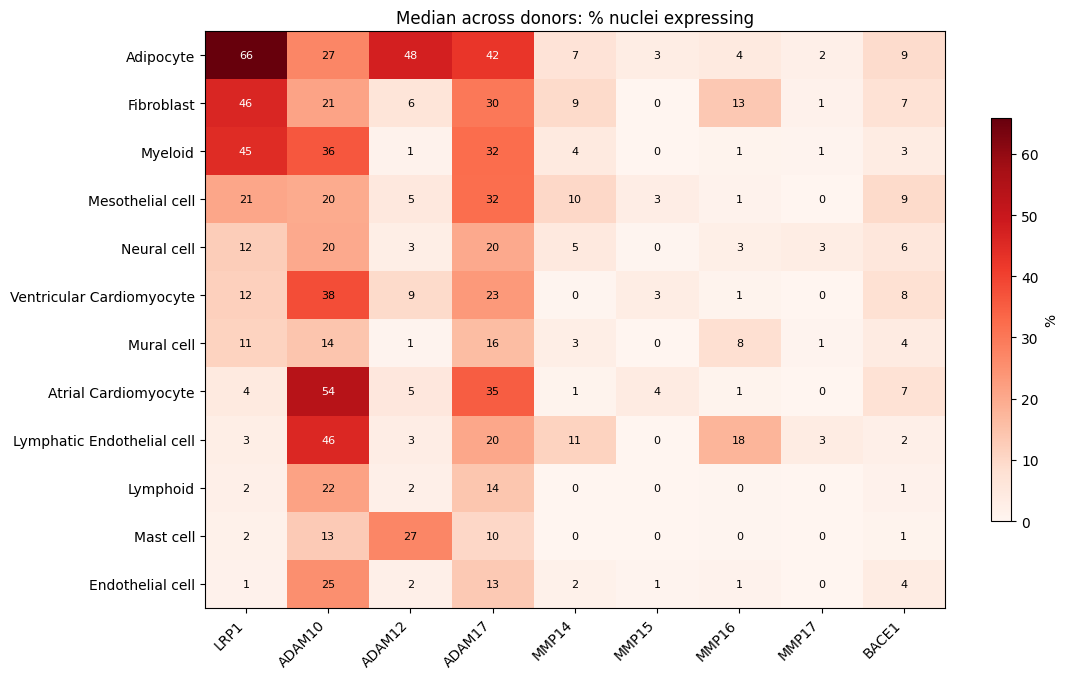

In [11]:
nuc = donor[donor['source'] == 'Nuclei']
heat = nuc.pivot_table(index='cell_type', columns='gene', values='pct', aggfunc='median')[GENES]
heat = heat.sort_values('LRP1', ascending=False)
heat.round(2).to_csv(OUT / '02_donor_median_pct_nuclei.csv')

fig, ax = plt.subplots(figsize=(1.0 * len(GENES) + 2.5, 0.45 * len(heat) + 1.5))
im = ax.imshow(heat.values, cmap='Reds', aspect='auto', vmin=0)
ax.set_xticks(range(len(GENES)))
ax.set_xticklabels(GENES, rotation=45, ha='right')
ax.set_yticks(range(len(heat)))
ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8,
                    color='white' if v > np.nanmax(heat.values) * 0.6 else 'black')
ax.set_title('Median across donors: % nuclei expressing')
plt.colorbar(im, ax=ax, shrink=0.7, label='%')
plt.tight_layout()
plt.savefig(OUT / '02_heatmap_donor_median_pct_nuclei.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. 섬유모세포 vs 다른 세포 유형: 통계 검정

같은 공여자 안에서 섬유모세포의 값과 다른 세포 유형의 값을 짝지어 비교합니다(윌콕슨 부호순위 검정, 핵 데이터).

표를 읽는 법:
- **n_donors**: 두 세포 유형이 모두 충분히 있는 공여자 수
- **fb_higher**: 그중 섬유모세포 쪽이 더 높은 공여자 수. 가장 직관적인 숫자입니다.
- **fb_median / other_median**: 각 세포 유형의 공여자 중앙값
- **p_adj**: 여러 번 비교한 것을 보정한 p값(Holm 보정). 0.05보다 작으면 차이가 우연이라고 보기 어렵습니다.

발현 세포 비율(pct)과 평균 발현량(mean) 두 지표로 각각 검정합니다. 두 지표의 결론이 같으면 더 믿을 수 있습니다.

In [12]:
def fb_vs_others(value, source='Nuclei', min_donors=6):
    rows = []
    d = donor[donor['source'] == source]
    for gene in GENES:
        wide = d[d['gene'] == gene].pivot(index='donor', columns='cell_type', values=value)
        if FB not in wide:
            continue
        for other in wide.columns.drop(FB):
            pair = wide[[FB, other]].dropna()
            if len(pair) < min_donors:
                continue
            diff = pair[FB] - pair[other]
            p = wilcoxon(diff).pvalue if (diff != 0).any() else 1.0
            rows.append(dict(gene=gene, other=other, n_donors=len(pair),
                             fb_higher=int((diff > 0).sum()),
                             fb_median=pair[FB].median(), other_median=pair[other].median(), p=p))
    res = pd.DataFrame(rows)
    res['p_adj'] = np.nan
    for gene, ix in res.groupby('gene').groups.items():
        res.loc[ix, 'p_adj'] = multipletests(res.loc[ix, 'p'], method='holm')[1]
    return res

test_pct = fb_vs_others('pct')
test_mean = fb_vs_others('mean')
test_pct.round(4).to_csv(OUT / '02_test_fb_vs_others_pct.csv', index=False)
test_mean.round(4).to_csv(OUT / '02_test_fb_vs_others_mean.csv', index=False)

print('[LRP1: 섬유모세포 vs 다른 세포 유형, 발현 세포 비율 기준]')
test_pct[test_pct['gene'] == 'LRP1'].sort_values('other_median', ascending=False).round(4)

[LRP1: 섬유모세포 vs 다른 세포 유형, 발현 세포 비율 기준]


,gene,other,n_donors,fb_higher,fb_median,other_median,p,p_adj
0,LRP1,Adipocyte,21,5,44.6245,65.8879,0.0016,0.0064
7,LRP1,Myeloid,22,13,45.8558,44.5590,0.1982,0.1982
8,LRP1,Neural cell,21,21,44.6245,12.3967,0.0000,0.0000
9,LRP1,Ventricular Cardiomyocyte,19,19,43.9354,11.7097,0.0000,0.0000
6,LRP1,Mural cell,22,22,45.8558,11.1119,0.0000,0.0000
1,LRP1,Atrial Cardiomyocyte,22,22,45.8558,4.2014,0.0000,0.0000
3,LRP1,Lymphatic Endothelial cell,6,6,60.0957,2.7746,0.0312,0.0625
4,LRP1,Lymphoid,19,19,47.9750,2.0661,0.0000,0.0000
5,LRP1,Mast cell,9,9,44.6245,1.6393,0.0039,0.0117
2,LRP1,Endothelial cell,22,22,45.8558,1.4524,0.0000,0.0000


In [13]:
print('[LRP1: 섬유모세포 vs 다른 세포 유형, 평균 발현량 기준]')
test_mean[test_mean['gene'] == 'LRP1'].sort_values('other_median', ascending=False).round(4)

[LRP1: 섬유모세포 vs 다른 세포 유형, 평균 발현량 기준]


,gene,other,n_donors,fb_higher,fb_median,other_median,p,p_adj
0,LRP1,Adipocyte,21,5,0.9650,1.1553,0.0421,0.0938
7,LRP1,Myeloid,22,14,0.9691,0.9025,0.2099,0.2099
8,LRP1,Neural cell,21,21,0.9650,0.2531,0.0000,0.0000
6,LRP1,Mural cell,22,22,0.9691,0.2169,0.0000,0.0000
9,LRP1,Ventricular Cardiomyocyte,19,19,0.8946,0.1308,0.0000,0.0000
1,LRP1,Atrial Cardiomyocyte,22,22,0.9691,0.0500,0.0000,0.0000
3,LRP1,Lymphatic Endothelial cell,6,6,1.3226,0.0469,0.0312,0.0938
4,LRP1,Lymphoid,19,19,1.0066,0.0366,0.0000,0.0000
5,LRP1,Mast cell,9,9,0.8587,0.0332,0.0039,0.0156
2,LRP1,Endothelial cell,22,22,0.9691,0.0288,0.0000,0.0000


### sheddase별 요약

유전자마다 "섬유모세포가 몇 개의 다른 세포 유형보다 유의하게 높은가"를 셉니다(발현 세포 비율 기준, p_adj < 0.05이면서 섬유모세포 중앙값이 더 높은 경우).

In [14]:
sig = test_pct.assign(fb_sig_higher=(test_pct['p_adj'] < 0.05) & (test_pct['fb_median'] > test_pct['other_median']),
                      fb_sig_lower=(test_pct['p_adj'] < 0.05) & (test_pct['fb_median'] < test_pct['other_median']))
summary = sig.groupby('gene').agg(n_compared=('other', 'size'),
                                   fb_sig_higher=('fb_sig_higher', 'sum'),
                                   fb_sig_lower=('fb_sig_lower', 'sum'),
                                   fb_median_pct=('fb_median', 'first')).loc[GENES]
summary.round(2).to_csv(OUT / '02_summary_fb_rank.csv')
summary.round(2)

,n_compared,fb_sig_higher,fb_sig_lower,fb_median_pct
gene,,,,
LRP1,10,7,1,44.62
ADAM10,10,2,4,20.47
ADAM12,10,5,2,6.30
ADAM17,10,5,1,29.70
MMP14,10,8,0,9.28
MMP15,10,1,4,0.15
MMP16,10,9,0,13.00
MMP17,10,6,1,1.29
BACE1,10,5,1,6.89


In [15]:
for f in sorted(OUT.glob('02_*')):
    print(f.name)

02_by_cell_type.csv
02_donor_boxplot_LRP1.png
02_donor_level.csv
02_donor_median_pct_nuclei.csv
02_dotplot_LRP1_sheddase.png
02_dotplot_markers.png
02_heatmap_donor_median_pct_nuclei.png
02_overview_cells_per_type.csv
02_summary_fb_rank.csv
02_test_fb_vs_others_mean.csv
02_test_fb_vs_others_pct.csv
02_umap_LRP1.png
